In [1]:
import librosa
from glob import glob
import os
from tqdm import tqdm

In [2]:
#Ερωτημα 2
def parse_free_digits(directory):
    files = glob(os.path.join(directory, "*.wav"))
    files = [f.replace("\\", "/") for f in files]


    fnames = [f.split("/")[-1].rsplit(".", 1)[0] for f in files]


    digits = [
        "".join(c for c in f if c.isalpha())
        for f in fnames
    ]

  
    speakers = [
        int("".join(c for c in f if c.isdigit()))
        for f in fnames
    ]

    def read_wav(f):
        wav, sr = librosa.load(f, sr=16000)
        #sr = Sampling Rate = Συχνότητα Δειγματοληψίας = Πόσα δείγματα παίρνουμε ανα δευτερόλεπτο (sr = 16000)
        #wav = Voice message waveform = Κυματομορφ΄ή ηχητικού μηνύματος
        return wav, sr

    recordings = [read_wav(f) for f in files]
    wavs = [r[0] for r in recordings]
    sample_rates = [r[1] for r in recordings]

    return digits, speakers, wavs
    

In [3]:
digits,speakers,wavs = parse_free_digits("digits")

In [4]:
wavs 

[array([-0.0007019 , -0.00088501, -0.00048828, ...,  0.00088501,
         0.00112915,  0.00091553], shape=(11891,), dtype=float32),
 array([ 9.1552734e-05, -3.0517578e-05, -2.7465820e-04, ...,
         6.4086914e-04,  1.1596680e-03,  1.3427734e-03],
       shape=(8821,), dtype=float32),
 array([-0.0010376 , -0.00109863, -0.00112915, ...,  0.00021362,
         0.00033569,  0.0007019 ], shape=(10485,), dtype=float32),
 array([1.2207031e-04, 9.1552734e-05, 3.0517578e-05, ..., 3.6621094e-04,
        4.5776367e-04, 3.6621094e-04], shape=(11695,), dtype=float32),
 array([-0.0005188 , -0.00045776, -0.00064087, ..., -0.00042725,
        -0.00030518, -0.00036621], shape=(14114,), dtype=float32),
 array([-0.00045776, -0.00018311,  0.00024414, ...,  0.00024414,
         0.00033569,  0.00015259], shape=(15323,), dtype=float32),
 array([-0.00021362, -0.00015259,  0.        , ..., -0.0005188 ,
        -0.00039673, -0.00045776], shape=(13610,), dtype=float32),
 array([ 1.5258789e-04,  2.1362305e-04, 

In [5]:
wavs[0].shape # 11891 δείγματα πλάτους κυματομορφής άρα 11891/16000 = 0.743 seconds 

(11891,)

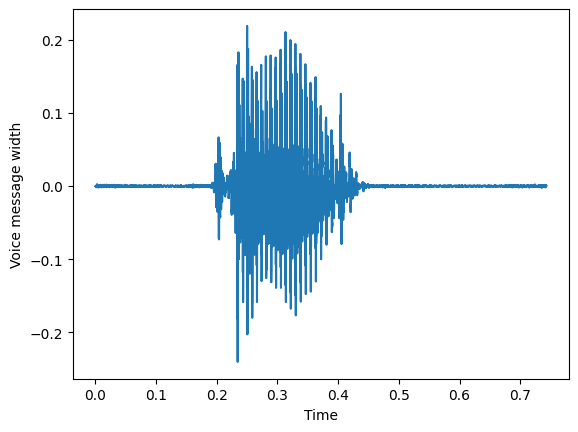

In [6]:
import matplotlib.pyplot as plt
import numpy as np
time = np.arange(len(wavs[0]))/16000
plt.plot( time, wavs[0])
plt.xlabel('Time')
plt.ylabel('Voice message width')
plt.show()

Το ακατέργαστο σήμα δεν είναι καλό χαρακτηριστικό για αναγνώριση για αυτό κόβουμε το σήμα σε μικρά παράθυρα 25ms με βήμα 10 ms άρα τα παράθυρα επικαλύπτονται. Σε κάθε παράθυρο έχουμε 400 αριθμούς οι οποιοί περιγράφουν την κυματομορφή. Από κάθε παράθυρο των 400 δειγμάτων εξάγουμε 13 MFCCs, οπότε κάθε παράθυρο γίνεται 1×13 διάνυσμα. Μαζί με τις πρώτες και τις δεύτερες παραγώγους 1x39. Κάθε εκφώνηση γίνεται πίνακας A x 39 όπου A ο αριθμός των παραθύρων και διαφέρει ανάλογα με τη διάρκεια κάθε ηχητικού μηνύματος. Για το wav[0]: 11891/16000 = 0.74 -> Α = 75

Για να κάνουμε extract τα MFCCs πρέπει να μετασχηματίσουμε το ακατέργαστο σήμα μέσω του FFT. Το librosa.feature.mfcc πραγματοποιεί τον παραπάνω μετασχηματισμό.

In [7]:
#Question 3
def extract_features(wavs, n_mfcc=13, Fs=16000):
    # Extract MFCCs for all wavs
    window = 25 * Fs // 1000
    step = 10 * Fs // 1000
    frames = [
        librosa.feature.mfcc(
            y=wav, sr=Fs, n_fft=window, hop_length=step, n_mfcc=n_mfcc
        ).T
        for wav in tqdm(wavs, desc="Extracting mfcc features...")
    ]

    print("Feature extraction completed with {} mfccs per frame".format(n_mfcc))
    delta1 = []
    delta2 = []
    for f in frames:
        delta1.append(librosa.feature.delta(f, order=1,axis=0))
        delta2.append(librosa.feature.delta(f, order=2,axis=0))

    return frames, delta1, delta2
frames,d1,d2 = extract_features(wavs)

Extracting mfcc features...: 100%|██████████| 133/133 [00:00<00:00, 415.80it/s]

Feature extraction completed with 13 mfccs per frame


To frames είναι μια λίστα με 133 στοιχεία όπου κάθε στοιχείο περιγράφει ένα ηχητικό μήνυμα. Κάθε στοιχείο είναι ένας πίνακας Ax13 όπου A είναι ο αριθμός των παραθύρων του αντίστοιχου ηχητικού. Κάθε γραμμή του πίνακα είναι τα MFCCs του αντίστοιχου παραθύρου

In [8]:
Matrix = frames[0] # 1st Voice message
Matrix.shape 

(75, 13)

Το πρώτο στοιχείο της λίστας frames αποτελεί τον πρώτο πίνακα ο οποίος έχει διάσταση 75x13, δηλαδή τα στοιχεία που περιγράφουν πρώτο ηχητικό μήνυμα

In [9]:
Matrix[0]

array([-731.6329   ,   92.468414 ,  -25.632586 ,   -7.151409 ,
         -7.168664 ,  -15.451456 ,  -24.163605 ,  -10.651527 ,
         21.99081  ,    4.2388315,  -26.828121 ,  -15.56683  ,
         -1.8172473], dtype=float32)

Η πρώτη γραμμή του πίνακα αποτελείται από τα MFCCs του πρώτου παραθύρου

In [10]:
# Question4
def extract_mfccs(n):
    index = [i for i,d in enumerate(digits) if d == n]
    frames2 = [frames[i]  for i in index]
    mfcc1 = []
    mfcc2 = []
    for i in range(len(frames2)):
        for j in range(len(frames2[i])):
            mfcc1.append(frames2[i][j][0])
            mfcc2.append(frames2[i][j][1])
    return mfcc1, mfcc2
mfcc1_4, mfcc2_4 = extract_mfccs('four')
mfcc1_7, mfcc2_7 = extract_mfccs('seven')

Αυτό που θέλουμε να κάνουμε πρακτικά είναι να πάρουμε τα πρώτα 2 MFCCs από όλα τα ηχητικά μηνύματα που εκφωνούν τον αριθμό 4 και 7. Δηλαδή πρέπει να πάρουμε όλους τους πίνακες (15 για το ψηφίο 4 και 15 για το ψηφίο 7) και σε κάθε γραμμή να πάρουμε το 1ο και το 2ο στοιχείο. Αυτον τον αλγόριθμο υλοποιεί η παραπάνω συνάρτηση.

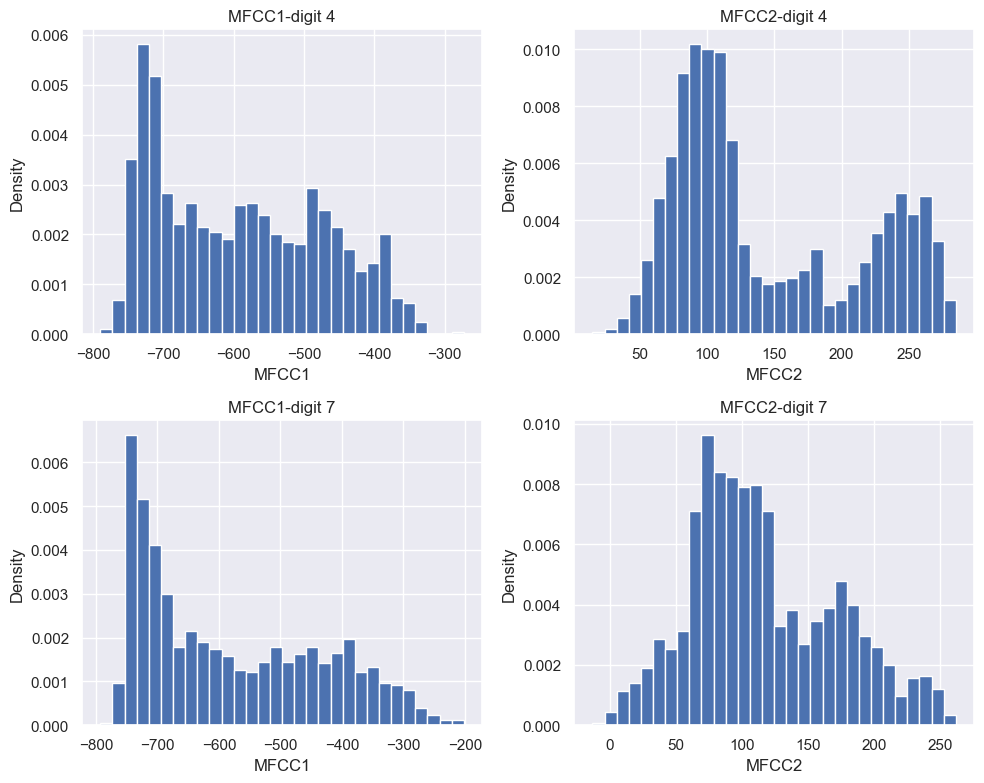

In [18]:
import seaborn as sns
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 8))
#MFFC1-4
plt.subplot(2, 2, 1)
plt.hist(mfcc1_4, bins=30, density = True)
plt.title("MFCC1-digit 4")
plt.xlabel('MFCC1')
plt.ylabel('Density')
#MFCC2-4
plt.subplot(2, 2, 2)
plt.hist(mfcc2_4, bins=30, density = True)
plt.title("MFCC2-digit 4")
plt.xlabel('MFCC2')
plt.ylabel('Density')
#MFCC1-7
plt.subplot(2, 2, 3)
plt.hist(mfcc1_7, bins=30, density = True)
plt.title("MFCC1-digit 7")
plt.xlabel('MFCC1')
plt.ylabel('Density')
#MFCC2-7
plt.subplot(2, 2, 4)
plt.hist(mfcc2_7, bins=30, density = True)
plt.title("MFCC2-digit 7")
plt.xlabel('MFCC2')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

Δημιουργούμε ιστογράμματα για τον 1ο και τον 2ο MFCC των ψηφίων 4 και 7. Χρησιμοποιούμε density=True, ώστε ο άξονας y να δείχνει πυκνότητα και η σύγκριση να πραγματοποιείται ανεξάρτητα από το πλήθος των παραθύρων. Παρατηρείται σημαντική διασπορά μέσα σε κάθε ψηφίο. Αυτό οφείλεται στους διαφορετικούς εκφωνητές και στο γεγονός ότι ορισμένα παράθυρα είναι κενά (χωρίς ήχο) πριν και μετά την εκφώνηση. Το MFCC1 έχει παρόμοια κατανομή μεταξύ των δύο ψηφίων, επόμενως δεν τα διαχωρίζει. Στο MFCC2 παρατηρούνται ορισμένες διαφορές μεταξύ των κατανομών αλλά και πάλι στο μεγαλύτερο μέρος επικαλύπτονται.

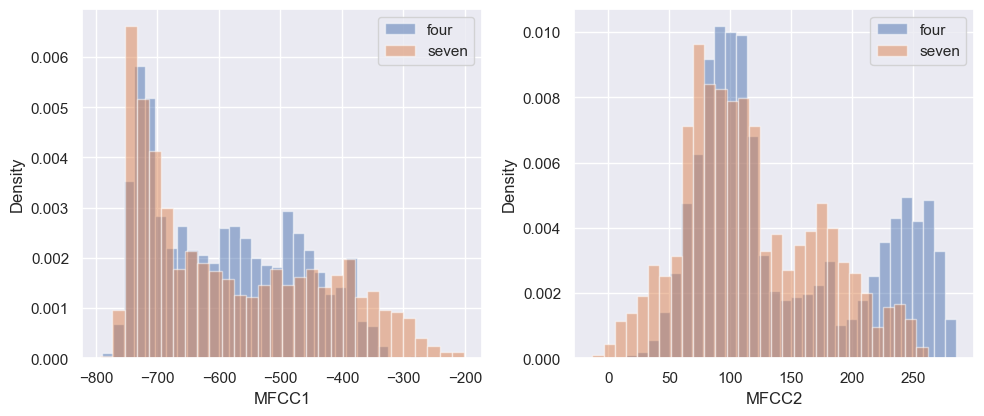

In [12]:
plt.figure(figsize=(10, 8))
plt.subplot(2,2,1)
plt.hist(mfcc1_4, bins=30, density=True, alpha=0.5, label='four')
plt.hist(mfcc1_7, bins=30, density=True, alpha=0.5, label='seven')
plt.xlabel('MFCC1')
plt.ylabel('Density')
plt.legend()
plt.subplot(2,2,2)
plt.hist(mfcc2_4, bins=30, density=True, alpha=0.5, label='four')
plt.hist(mfcc2_7, bins=30, density=True, alpha=0.5, label='seven')
plt.xlabel('MFCC2')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

Η διαδικασία δημιουργίας των MFCCs είναι η ακόλουθη :

Ακατέργαστος Ήχος -> Fourier Transformation -> Mel Filters -> Log Transformation -> DCT -> MFCCs

Τα MFSCs είναι η παραπάνω διαδικασία αλλά σταματάμε στο Log Transformation.

Η παρακάτω συνάρτηση δέχεται σαν όρισμα το ηχητικό μήνυμα σε μορφή .wav και υπολογίζει τα MFSCs. 

In [13]:
def mfsc(wav, n_mels = 13, Fs=16000):
    window = 25*Fs//1000
    step = 10*Fs//1000
    mel = librosa.feature.melspectrogram(y=wav, sr = Fs, n_fft = window, hop_length = step,n_mels = n_mels).T
    return np.log(1e-10 + mel)

In [14]:
def idx(n):
    return [i for i,d in enumerate(digits) if d == n][0:2]
mfsc4_a, mfsc4_b = [mfsc(wavs[i]) for i in idx('four')]
mfsc7_a, mfsc7_b = [mfsc(wavs[i]) for i in idx('seven')]
corr4a = np.corrcoef(mfsc4_a.T)
corr4b = np.corrcoef(mfsc4_b.T)
corr7a = np.corrcoef(mfsc7_a.T)
corr7b = np.corrcoef(mfsc7_b.T)

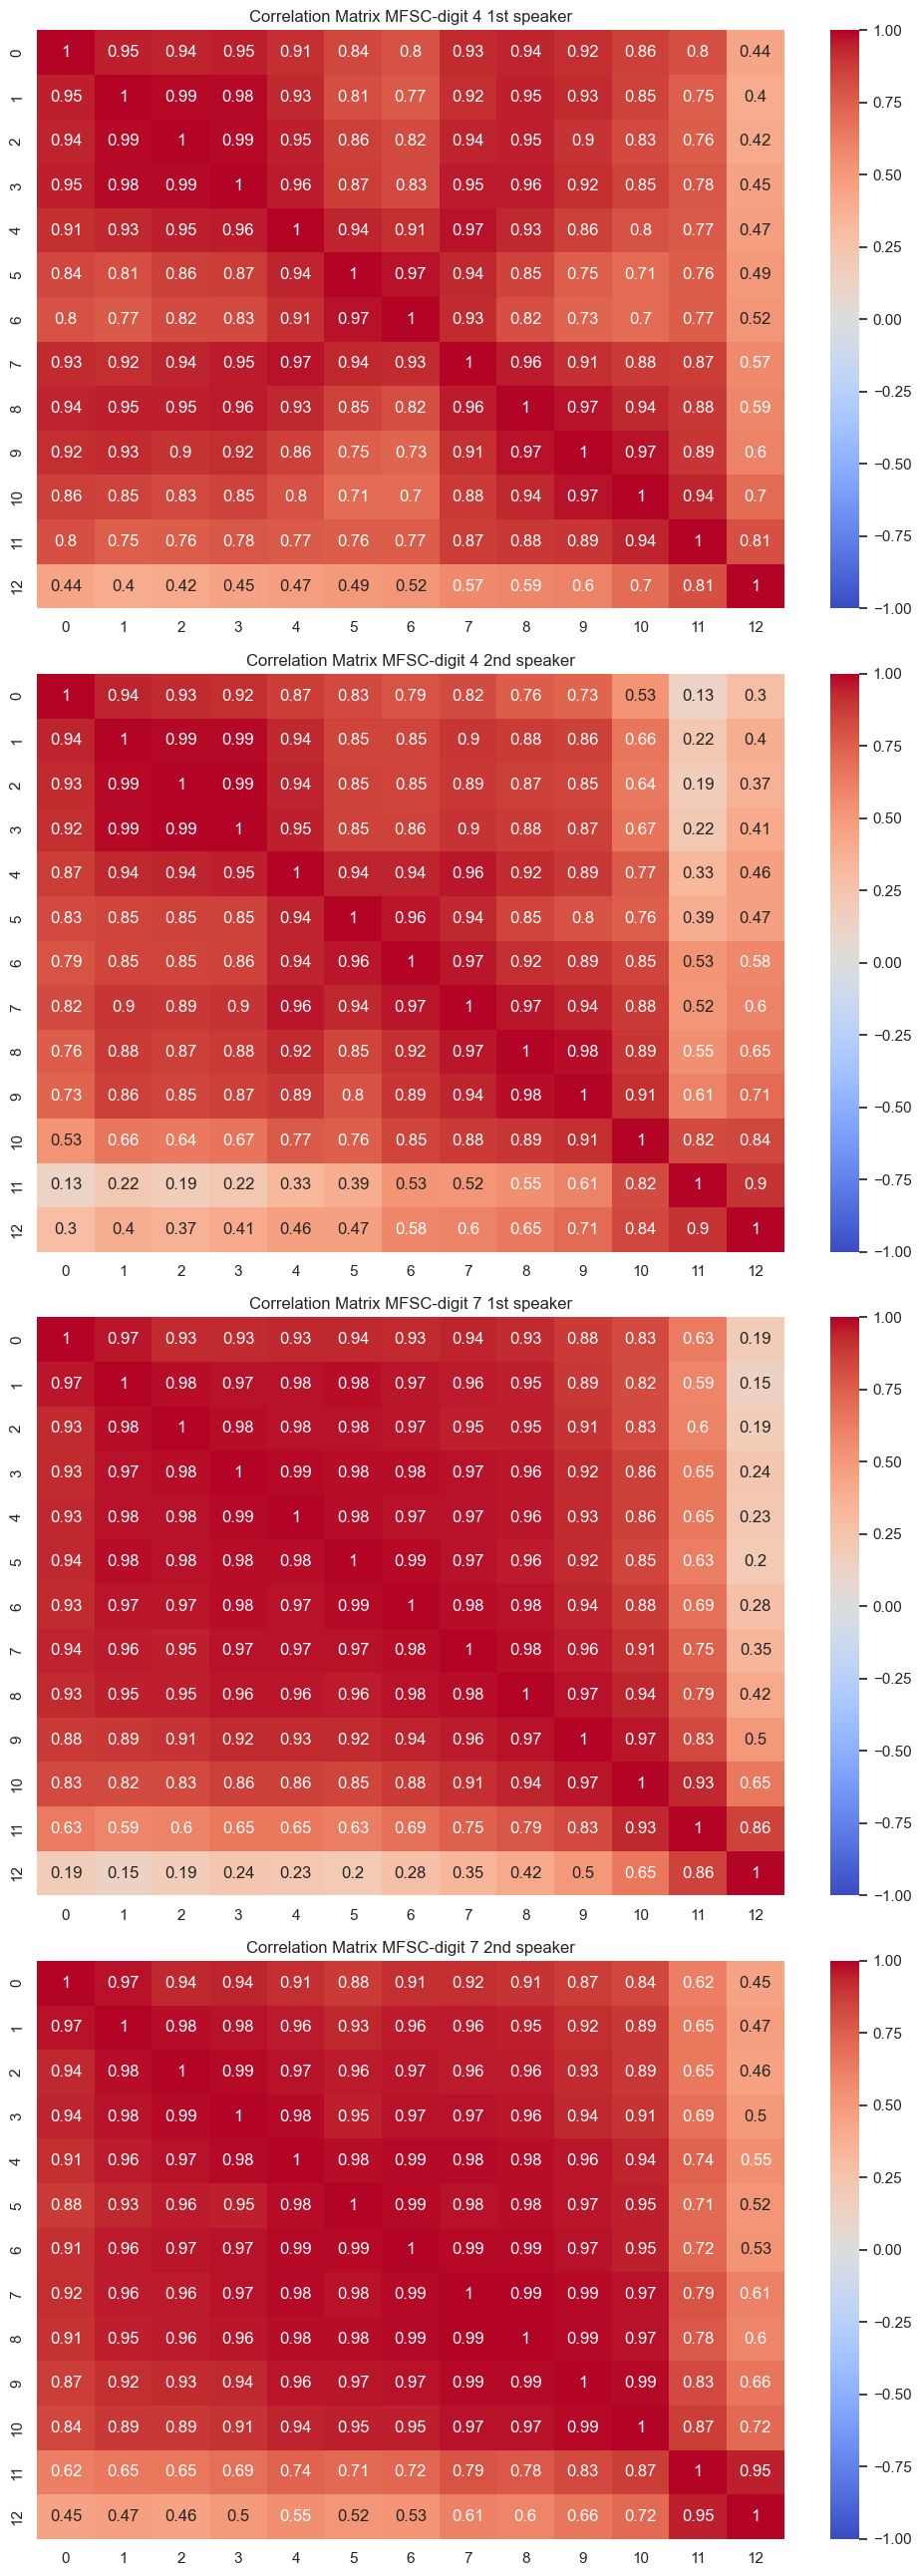

In [15]:
plt.figure(figsize = (10,26))
plt.subplot(4,1,1)
sns.heatmap(corr4a, annot= True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 4 1st speaker')

plt.subplot(4,1,2)
sns.heatmap(corr4b, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 4 2nd speaker')

plt.subplot(4,1,3)
sns.heatmap(corr7a, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 7 1st speaker')

plt.subplot(4,1,4)
sns.heatmap(corr7b, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 7 2nd speaker')

plt.tight_layout()
plt.show()

Παρατηρείται ότι τα MFSCs είναι έντονα θετικά συσχετισμένα με τη συσχέτιση να μειώνεται σημαντικά μόνο στο τελευταίο φίλτρο και στους δύο ομιλητές και στα δύο ψηφία.

In [16]:
corr4_mfcc1 = np.corrcoef(frames[idx('four')[0]].T)
corr4_mfcc2 = np.corrcoef(frames[idx('four')[1]].T)
corr7_mfcc1 = np.corrcoef(frames[idx('seven')[0]].T)
corr7_mfcc2 = np.corrcoef(frames[idx('seven')[1]].T)

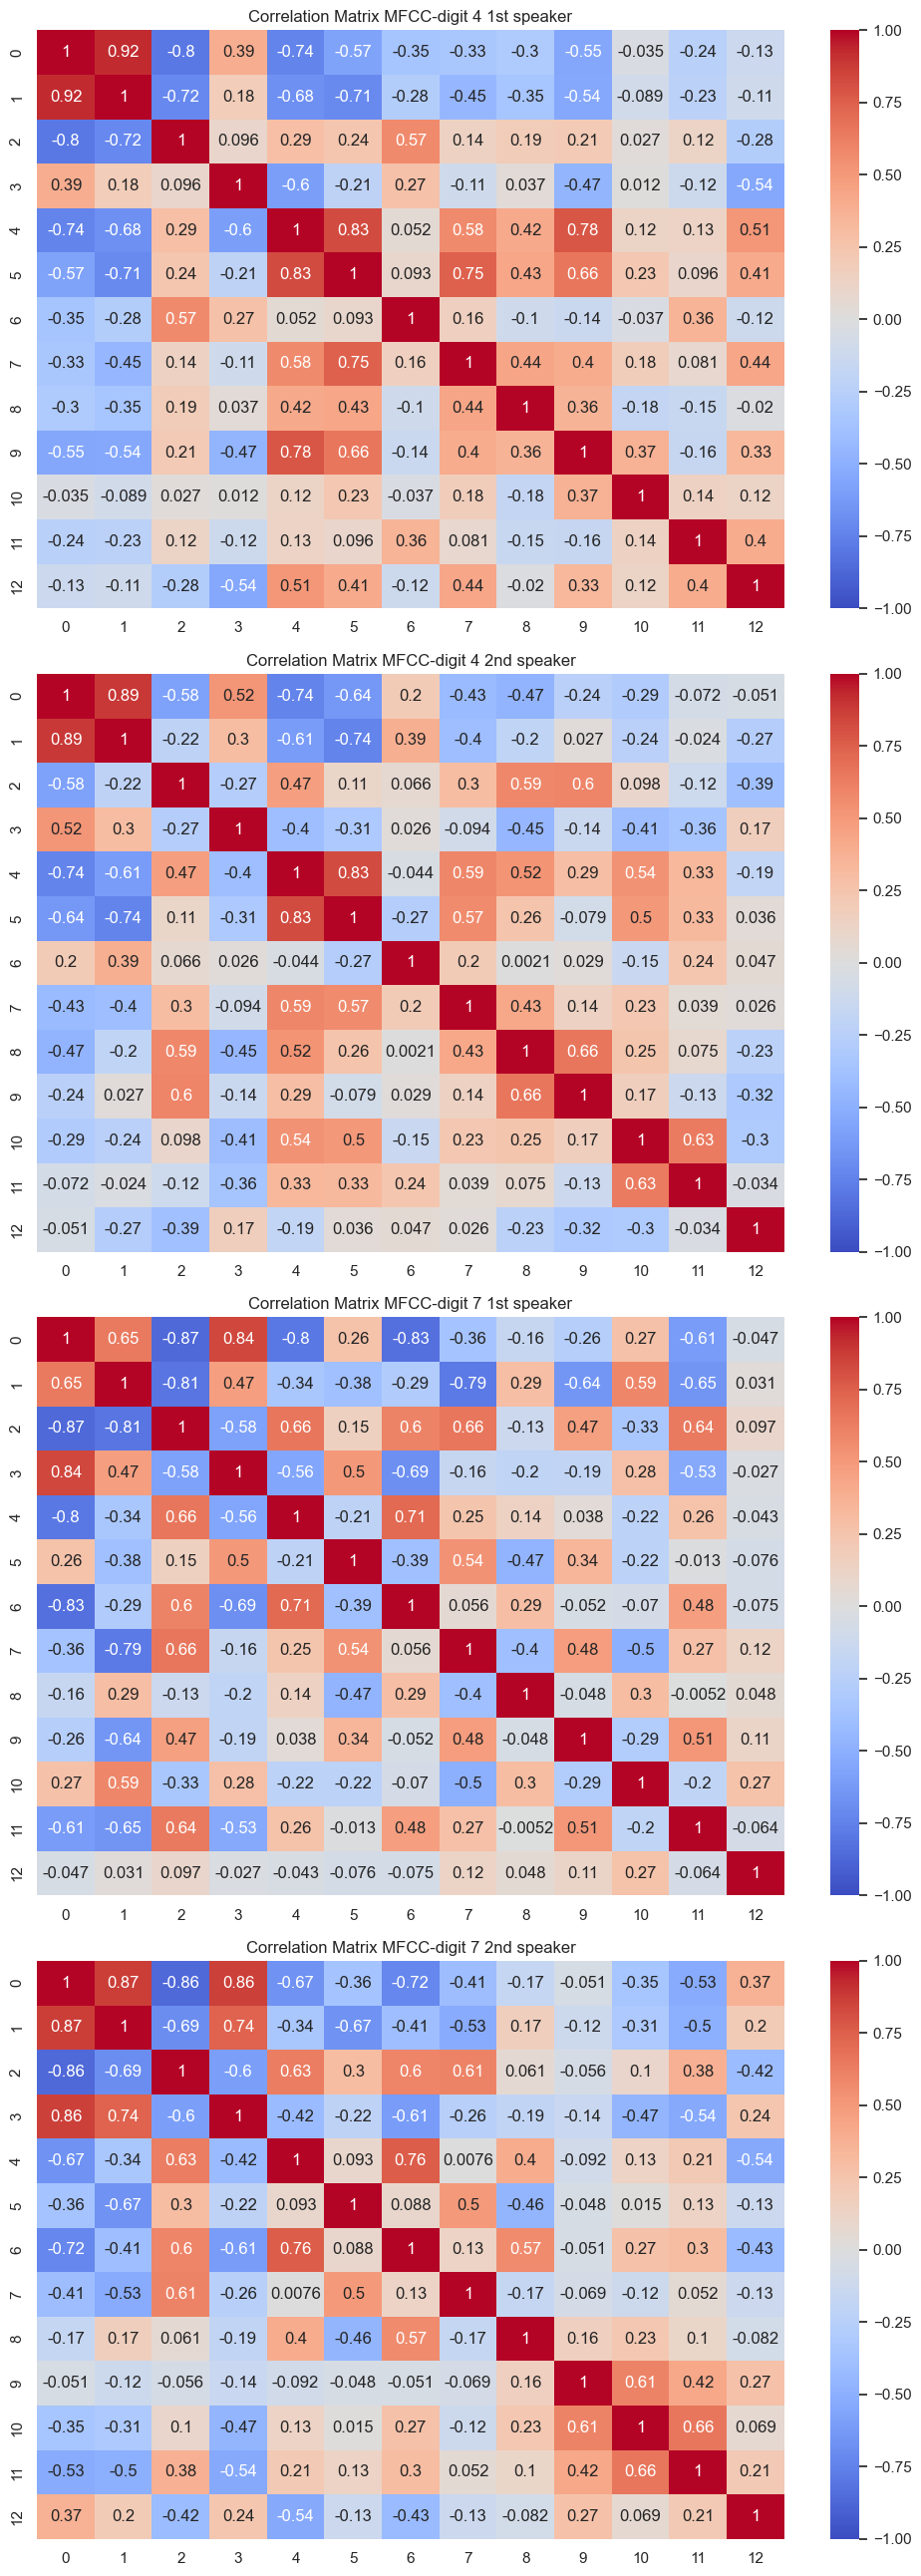

In [17]:
plt.figure(figsize = (10,26))
plt.subplot(4,1,1)
sns.heatmap(corr4_mfcc1, annot= True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 4 1st speaker')

plt.subplot(4,1,2)
sns.heatmap(corr4_mfcc2, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 4 2nd speaker')

plt.subplot(4,1,3)
sns.heatmap(corr7_mfcc1, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 7 1st speaker')

plt.subplot(4,1,4)
sns.heatmap(corr7_mfcc2, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 7 2nd speaker')

plt.tight_layout()
plt.show()

Από τα correlation heatmaps των MFCCs παρατηρείται ότι σε αντίθεση με τα MFSCs όπου σχεδόν όλα τα ζεύγη έχουν υψηλή συσχέτιση οι συσχετίσεις στα MFCCs είναι πολύ μικρότερες κατά απόλυτη τιμή και με διαφορετικά πρόσημα. Έτσι αντιλαμβανόμαστε ότι το DCT (Discrete Cosine Transform - Διακριτικός Μετασχηματισμός Συνημιτόνου) αποσυσχετίζει σε μεγάλο βαθμό τα χαρακτηριστικά.